# Crossing the Stability Threshold: Particle Filter Behaviour as $\rho(F)$ Passes 1

**Part 5 of a supervised research project — Dr Mathieu Gerber, University of Bristol**

## The question

Every result in Parts 1–4 was obtained at a single setting of the state transition matrix:
$b = 0.9$ in one dimension, or $F$ rescaled to spectral radius $0.9$ in $d$ dimensions. That value
is comfortably inside the stable region, and stability of the *model* was treated as a background
assumption rather than a variable.

This notebook makes it the variable:

> **How does particle filter accuracy and stability change as the spectral radius of the state
> transition matrix crosses 1, and does coupling between state dimensions affect this behaviour?**

## Why $\rho(F) = 1$ is the threshold

The state recursion is $x_t = F x_{t-1} + v_t$. Rolling it forward from $x_0$,

$$x_t = F^t x_0 + \sum_{k=0}^{t-1} F^k v_{t-k}.$$

The behaviour of $F^t$ is governed by the **spectral radius** $\rho(F) = \max_i |\lambda_i(F)|$, the
largest absolute eigenvalue:

| | | |
|---|---|---|
| $\rho(F) < 1$ | $F^t \to 0$ | the state forgets its past geometrically; a stationary distribution exists |
| $\rho(F) = 1$ | $F^t$ neither grows nor decays | knife-edge random walk; no stationary distribution |
| $\rho(F) > 1$ | $F^t$ diverges | the state variance grows without bound |

Two things are worth stating plainly, because both are easy to get wrong.

**It is a property of the eigenvalues, not of the entries of $F$.** A matrix whose every entry is
well below 1 can still be explosive. Section 6 exhibits one.

**"Explosive" is an asymptotic statement.** $\rho(F) > 1$ means the state variance is unbounded as
$t \to \infty$. It does not mean large values appear immediately once $b$ exceeds 1: at $b = 1.01$
the state is still small after 200 steps.

## Scope

Following Dr Gerber's feedback, the regime of practical interest is
$|\rho(F)| \leq 1$: a hidden state whose variance grows without bound is not a realistic
modelling assumption. The grid below is therefore weighted towards the approach to the
threshold ($0.99$, $0.995$, $0.999$, $1.0$), and $\rho(F) = 1.1$ is retained only as a
**boundary check** — to show what crossing the threshold does — rather than as a regime
in its own right. Sections 8 and 9 use it for that purpose.

## What is actually being tested

An unstable *model* does not automatically imply an unstable *filter*. The Kalman filter can hold
its posterior uncertainty bounded for an explosive $F$, provided the observations constrain the
explosive directions. Whether that holds turns out to be the pivot of the whole notebook — and the
condition is not stability but **detectability**.

Fixed throughout: $Q = I$, $R = I$, $N = 1000$, and separate seeds for the data and for the particle
filter's own randomness, as in Parts 2–3. Only $b$ varies, and later $\texttt{coupling}$, $M$ and $T$.

## Roadmap

| Section | Content |
|---|---|
| 1 | The threshold in the code: building $F = b\,I_d$, and where existing helpers stop being valid |
| 2 | **Experiment 1** — one dimension, $F = b$ |
| 3 | Consistency: the 1D and $d = 1$ multidimensional paths agree above the threshold too |
| 4 | **Experiment 2** — diagonal $F = b\,I_d$ |
| 5 | **Experiment 3** — coupled $F$, same spectral radius |
| 6 | Entries versus eigenvalues: a stable-looking matrix that explodes |
| 7 | Error over time across the threshold, and at the dimensions where the cloud collapses |
| 8 | The numerical limit: where the measurement stops being real |
| 9 | **Experiment 4** — when the observations do *not* constrain the explosive direction |
| 10 | Error bars over 30 datasets |
| 11 | Summary |

Parts 1–4 are unchanged by anything here; this notebook only adds an axis.

---
### Setup

Same conventions and seeds as Parts 2–3 so the numbers line up. Two new helpers are defined here and
used throughout — a horizon limit, and a second normalisation of the error. Both are explained where
they are first needed (Sections 8 and 4 respectively).

In [1]:
import warnings
import numpy as np
import matplotlib.pyplot as plt

from filters import (
    # Part 1 scalar versions -- used unchanged in Section 2
    simulate_data, kalman_filter, particle_filter,
    # Part 2 multidimensional versions
    build_model, stationary_covariance, simulate_data_md,
    kalman_filter_md, particle_filter_md, run_case,
)

# --- The axis of this notebook ---
# Dr Gerber's feedback: only |rho(F)| <= 1 is of practical interest, so the grid is
# weighted below the threshold. b = 1.1 is retained only as a boundary check, to show
# what crossing it does; it is not treated as a regime of interest.
B_GRID = [0.5, 0.9, 0.99, 0.995, 0.999, 1.0, 1.01, 1.1]   # target spectral radius of F
B_REF  = [0.9, 1.0, 1.01]                                 # canonical cases, for long runs

# --- Everything else held fixed ---
D, M       = 2, 2     # baseline dimensions
N_PART     = 1000     # particles
T_MAIN     = 200      # horizon for the sweeps (safe at every b in B_GRID -- see Section 8)
T_LONG     = 2000     # horizon for the stability test
N_SEEDS    = 8        # particle-filter seeds averaged in the sweeps
N_DATASETS = 30       # independent datasets for the error bars
DATA_SEED, PF_SEED = 42, 0

# Float64 carries ~16 significant digits. Once the state reaches 1e10, a difference
# of order 1 between two filters is near the edge of what can be resolved at all.
# Section 8 measures this directly; T_safe keeps the sweeps on the right side of it.
PRECISION_CAP = 1e10

plt.rcParams["figure.figsize"] = (10, 4.5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
C_STABLE, C_EDGE, C_EXPLODE = "tab:blue", "tab:orange", "tab:red"
_B_PALETTE = {0.5: "tab:cyan", 0.9: "tab:blue", 0.99: "tab:green",
              0.995: "tab:olive", 0.999: "tab:gray",
              1.0: "tab:orange", 1.01: "tab:red", 1.05: "tab:brown", 1.1: "tab:purple"}

class _BColor(dict):
    '''Colour per b value, with a stable fallback for values outside the main grid.'''
    def __missing__(self, key):
        return "tab:grey"

B_COLOR = _BColor(_B_PALETTE)

# Same known-spurious NumPy 2.0 + Apple Accelerate matmul warnings as Parts 2-3.
warnings.filterwarnings("ignore", message=".*encountered in matmul")
# Above the threshold the state legitimately overflows float64 at long horizons.
# That is the subject of Section 8, where it is measured rather than hidden.
warnings.filterwarnings("ignore", message=".*overflow encountered.*")
warnings.filterwarnings("ignore", message=".*invalid value encountered.*")


def T_safe(b, T_max=T_LONG, cap=PRECISION_CAP):
    '''Longest horizon at which b**T stays inside float64's usable precision.

    For b <= 1 there is no growth and no limit. For b > 1 the state grows like
    b**T, and once that exceeds `cap` the gap between two filters is smaller
    than the spacing between representable numbers. See Section 8.
    '''
    if b <= 1.0:
        return T_max
    return min(T_max, int(np.log(cap) / np.log(b)))


def state_size(res):
    '''RMS size of the true state per coordinate, ||x_t||/sqrt(d), at each step.

    The same sqrt(d) normalisation used by `pf_kf_gap`, so the two are comparable.
    '''
    return np.linalg.norm(res["x"], axis=1) / np.sqrt(res["d"])


def rel_to_state(res):
    '''PF-KF gap divided by the size of the state itself.

    A third normalisation, alongside the raw gap and `rel_gap` (= gap / posterior
    spread). This one is the diagnostic for Section 8: when the apparent error is
    really floating-point cancellation it sits at ~1e-16 here, whatever the raw
    gap says.
    '''
    return res["gap"] / np.maximum(state_size(res), 1e-12)


def sweep_b(b_grid, d=D, m=M, coupling=0.0, T=T_MAIN, n_seeds=N_SEEDS, **kw):
    '''Run one (d, M, coupling) configuration across a grid of b, averaging over seeds.'''
    out = []
    for b in b_grid:
        runs = [run_case(d, m, N=N_PART, T=T, b=b, coupling=coupling,
                         data_seed=DATA_SEED, pf_seed=s, **kw)
                for s in range(n_seeds)]
        out.append({
            "b": b, "d": d, "M": m,
            "mean_gap": np.mean([r["mean_gap"] for r in runs]),
            "rel_gap":  np.mean([r["rel_gap"] for r in runs]),
            "post_sd":  np.mean([r["post_sd"] for r in runs]),
            "min_ess":  np.mean([r["min_ess"] for r in runs]),
            "resamp":   np.mean([r["resampled"].sum() for r in runs]),
            "rel_state": np.mean([rel_to_state(r).mean() for r in runs]),
            "x_max":    np.abs(runs[0]["x"]).max(),
            "state_sd": state_size(runs[0]).mean(),
        })
    return out


def ci95(a):
    '''Half-width of a 95% confidence interval for the mean (as in Part 3).'''
    a = np.asarray(a, dtype=float)
    return 1.96 * a.std(ddof=1) / np.sqrt(len(a))


print(f"b grid         : {B_GRID}")
print(f"baseline       : d = {D}, M = {M}, N = {N_PART}, T = {T_MAIN}")
print(f"long horizon   : T = {T_LONG} at b = {B_REF}")
print(f"safe horizons  : " + ",  ".join(f"b={b}: T<={T_safe(b)}" for b in B_GRID))

b grid         : [0.5, 0.9, 0.99, 0.995, 0.999, 1.0, 1.01, 1.1]
baseline       : d = 2, M = 2, N = 1000, T = 200
long horizon   : T = 2000 at b = [0.9, 1.0, 1.01]
safe horizons  : b=0.5: T<=2000,  b=0.9: T<=2000,  b=0.99: T<=2000,  b=0.995: T<=2000,  b=0.999: T<=2000,  b=1.0: T<=2000,  b=1.01: T<=2000,  b=1.1: T<=241


---
## Section 1 — The threshold in the code

### Building $F = b\,I_d$

`build_model` constructs $F$ in three steps ([`filters.py`](filters.py)):

```python
base = np.eye(d)
if d > 1 and coupling != 0.0:
    base = base + coupling * (np.eye(d, k=1) + np.eye(d, k=-1))
rho_base = np.max(np.abs(np.linalg.eigvals(base)))
F = b * base / rho_base
```

The rescaling in the last line is what makes this notebook possible: whatever `coupling` and $d$ are,
the result has spectral radius **exactly** $b$, since $\rho(cA) = |c|\,\rho(A)$ and the
$\rho(\text{base})$ cancels. So the parameter named `b` *is* the stability knob,
and crossing the threshold is simply setting it above 1. No change to `filters.py` is needed.

One consequence matters for stating results precisely. With `coupling = 0` the base matrix is the
identity, so $F = b\,I_d$ and every eigenvalue equals $b$. With the **default** `coupling = 0.3`,
$b$ is still the spectral radius but it is no longer the diagonal — the diagonal comes out
substantially smaller. So `0.9 * identity`, as a literal matrix, requires `coupling = 0.0`. That is
the construction used for Experiment 2; Experiment 3 then puts the coupling back deliberately.

### Where the existing helpers stop being valid

`stationary_covariance(F, Q)` solves $P = FPF^\top + Q$ for the long-run spread of the state. That
equation has a solution **only when $\rho(F) < 1$** — a stationary distribution is exactly what an
explosive model does not have. The implementation inverts $I - F \otimes F$, which is singular at
$\rho(F) = 1$ and indefinite beyond it. The cell below shows both failure modes, because the second
one is silent and therefore the dangerous one.

In [2]:
print("F = b * I_d  requires coupling = 0.0:\n")
print(f"{'b':>6}{'diag(F)':>22}{'max |off-diag|':>17}{'rho(F)':>10}")
for b in B_GRID:
    F, _, _, _ = build_model(D, M, b=b, coupling=0.0)
    off = np.abs(F - np.diag(np.diag(F))).max()
    rho = np.max(np.abs(np.linalg.eigvals(F)))
    print(f"{b:>6}{str(np.round(np.diag(F), 3)):>22}{off:>17.1e}{rho:>10.4f}")

# For contrast: the default coupling keeps rho = b but moves the diagonal away from it.
F_c, _, _, _ = build_model(4, 4, b=0.9, coupling=0.3)
print(f"\nContrast -- default coupling=0.3 at d=4:  diag(F)[0] = {np.diag(F_c)[0]:.4f}  "
      f"but rho(F) = {np.max(np.abs(np.linalg.eigvals(F_c))):.4f}")
print("So 'F = 0.9 * identity' as a literal matrix means coupling = 0.0, not the default.")

F = b * I_d  requires coupling = 0.0:

     b               diag(F)   max |off-diag|    rho(F)
   0.5             [0.5 0.5]          0.0e+00    0.5000
   0.9             [0.9 0.9]          0.0e+00    0.9000
  0.99           [0.99 0.99]          0.0e+00    0.9900
 0.995         [0.995 0.995]          0.0e+00    0.9950
 0.999         [0.999 0.999]          0.0e+00    0.9990
   1.0               [1. 1.]          0.0e+00    1.0000
  1.01           [1.01 1.01]          0.0e+00    1.0100
   1.1             [1.1 1.1]          0.0e+00    1.1000

Contrast -- default coupling=0.3 at d=4:  diag(F)[0] = 0.6059  but rho(F) = 0.9000
So 'F = 0.9 * identity' as a literal matrix means coupling = 0.0, not the default.


In [3]:
print("stationary_covariance(F, Q) across the threshold:\n")
for b in B_GRID:
    F, Q, _, _ = build_model(D, M, b=b, coupling=0.0)
    try:
        P = stationary_covariance(F, Q)
        bad = "   <-- NEGATIVE variance: silently meaningless" if np.any(np.diag(P) <= 0) else ""
        print(f"  b={b:>5}:  diag(P) = {np.round(np.diag(P), 4)}{bad}")
    except np.linalg.LinAlgError as e:
        print(f"  b={b:>5}:  LinAlgError: {e}   <-- I - F(x)F is singular exactly at the threshold")

print("\nBelow 1 the answer is a genuine variance. At 1 the solve fails loudly, which is fine.")
print("Above 1 it returns a negative 'variance' and raises nothing at all -- so this function")
print("must not be called for b >= 1. Nothing below does; Part 2 Section 4 did, at b = 0.9.")

stationary_covariance(F, Q) across the threshold:

  b=  0.5:  diag(P) = [1.3333 1.3333]
  b=  0.9:  diag(P) = [5.2632 5.2632]
  b= 0.99:  diag(P) = [50.2513 50.2513]
  b=0.995:  diag(P) = [100.2506 100.2506]
  b=0.999:  diag(P) = [500.2501 500.2501]
  b=  1.0:  LinAlgError: Singular matrix   <-- I - F(x)F is singular exactly at the threshold
  b= 1.01:  diag(P) = [-49.7512 -49.7512]   <-- NEGATIVE variance: silently meaningless
  b=  1.1:  diag(P) = [-4.7619 -4.7619]   <-- NEGATIVE variance: silently meaningless

Below 1 the answer is a genuine variance. At 1 the solve fails loudly, which is fine.
Above 1 it returns a negative 'variance' and raises nothing at all -- so this function
must not be called for b >= 1. Nothing below does; Part 2 Section 4 did, at b = 0.9.


**Conclusion.** With `coupling = 0.0` the construction returns exactly $b\,I_d$: off-diagonal entries are zero to
machine precision and $\rho(F) = b$ at every $b$ tested. The default `coupling = 0.3` also gives
$\rho(F) = b$, but its diagonal is $0.6059$ at $d = 4$ — so "$F = 0.9 \times$ identity" as a literal
matrix requires `coupling = 0`, and Experiment 2 uses that.

`stationary_covariance` behaves in three distinct ways across the threshold. Below it the answer is a
genuine variance, growing from $1.33$ at $b = 0.5$ to $50.25$ at $b = 0.99$ — the stationary spread
diverging as the threshold is approached, which is itself the right behaviour. Exactly at $b = 1$ the
solve fails loudly with a `LinAlgError`. Above it the function returns a **negative** variance
($-49.75$ at $b = 1.01$, $-4.76$ at $b = 1.1$) and raises nothing at all. The silent failure is the
dangerous one, and it is the only thing in `filters.py` that this notebook has to route around.

---
## Section 2 — Experiment 1: one dimension, $F = b$

The cleanest possible form of the question. In one dimension $F$ is a single number, there is no
coupling, no observation geometry and no dimension effect — only $b$ crossing 1. Whatever happens
here is attributable to the threshold and nothing else.

This also fixes a point of notation worth being explicit about. Part 1 calls the transition
coefficient `b` and the observation coefficient `a`; Part 2 onwards calls them $F$ and $H$. They are
the same two objects, and the scalar case is the $d = 1$ case of the matrix one:

$$F = \begin{pmatrix} b \end{pmatrix}, \qquad H = \begin{pmatrix} a \end{pmatrix}.$$

So "$F = 0.9$" and "$F = 0.9\,I_d$" are the same model at $d = 1$, and $F = 1$ is the stability
threshold in both.

**The functions used here are Part 1's, unchanged.** `simulate_data`, `kalman_filter` and
`particle_filter` all take `b` as an argument and none of them assumes $b < 1$, so the sweep needs no
new code. What we record at each $b$: how large the state becomes, the Kalman filter's steady-state
variance (its own statement of how uncertain it remains), the PF–KF gap, and the particle cloud's
health.

In [4]:
T1 = T_MAIN
rows_1d = []
for b in B_GRID:
    x, y = simulate_data(T=T1, b=b, Q=1.0, R=1.0, seed=DATA_SEED)
    # P0 = 0 matches how the data is generated (a known starting state) and how the
    # particle filter starts, so the two filters solve an identical problem. Part 1
    # used P0 = 1.0; Part 2 moved to this cleaner convention and we keep it here.
    m, P = kalman_filter(y, b=b, Q=1.0, R=1.0, P0=0.0)
    gaps, esss = [], []
    for s in range(N_SEEDS):
        est, ess, res = particle_filter(y, N=N_PART, b=b, Q=1.0, R=1.0, seed=s)
        gaps.append(np.abs(est - m))
        esss.append(ess)
    gap = np.mean(gaps, axis=0)
    rows_1d.append({"b": b, "x": x, "m": m, "P": P, "gap": gap,
                    "x_max": np.abs(x).max(), "kf_sd": np.sqrt(P[-1]),
                    "mean_gap": gap.mean(), "min_ess": np.mean([e.min() for e in esss])})

print(f"Experiment 1 -- one dimension, F = b, T = {T1}, N = {N_PART}, "
      f"averaged over {N_SEEDS} PF seeds:\n")
hdr = f"{'b':>6}{'max |x_t|':>13}{'state sd':>11}{'KF sd (end)':>13}{'mean gap':>11}{'gap/KF sd':>11}{'min ESS':>9}"
print(hdr); print("-" * len(hdr))
for r in rows_1d:
    print(f"{r['b']:>6}{r['x_max']:>13.4g}{r['x'].std():>11.4g}{r['kf_sd']:>13.4f}"
          f"{r['mean_gap']:>11.4f}{r['mean_gap']/r['kf_sd']:>11.4f}{r['min_ess']:>9.1f}")

Experiment 1 -- one dimension, F = b, T = 200, N = 1000, averaged over 8 PF seeds:

     b    max |x_t|   state sd  KF sd (end)   mean gap  gap/KF sd  min ESS
--------------------------------------------------------------------------
   0.5        2.794      1.095       0.7288     0.0238     0.0327     16.7
   0.9        7.085       2.06       0.7729     0.0266     0.0344     21.8
  0.99        9.815      3.832       0.7848     0.0270     0.0344     30.1
 0.995        9.336      3.936       0.7855     0.0268     0.0341     34.4
 0.999        9.743      3.972       0.7860     0.0272     0.0345     32.3
   1.0        9.829      3.973       0.7862     0.0264     0.0336     34.1
  1.01        9.527      3.904       0.7875     0.0270     0.0343     31.9
   1.1    2.623e+08  4.211e+07       0.7997     0.0288     0.0361     35.4


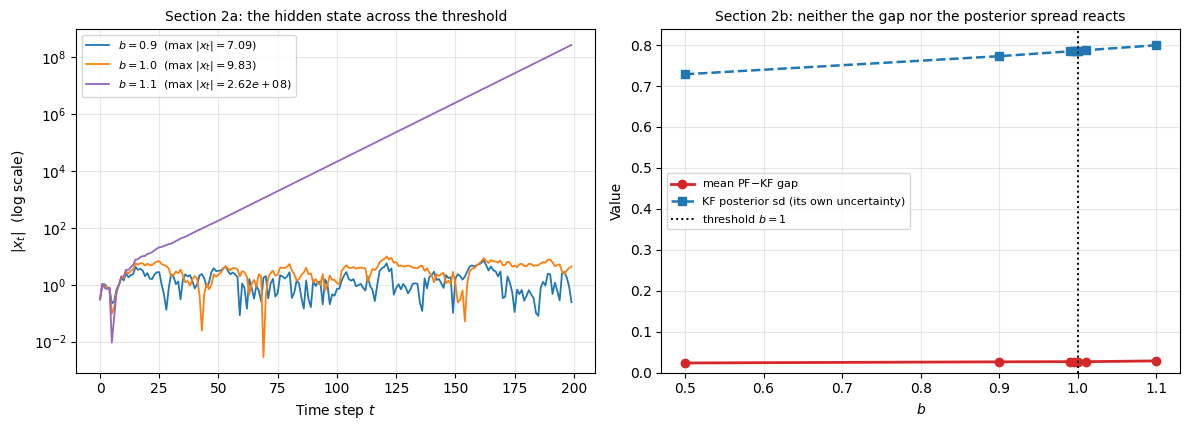

From b = 0.9 to b = 1.1:
  max |x_t|          7.09  ->  2.62e+08   (factor 3.7e+07)
  KF posterior sd    0.7729  ->  0.7997   (factor 1.035)
  mean PF-KF gap     0.0266  ->  0.0288   (factor 1.085)


In [5]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.4))

# Left: the state itself, on a log scale, so all three regimes fit on one axis.
for b in [0.9, 1.0, 1.1]:
    r = next(q for q in rows_1d if q["b"] == b)
    a1.semilogy(np.arange(T1), np.abs(r["x"]) + 1e-3, lw=1.3, color=B_COLOR[b],
                label=f"$b = {b}$  (max $|x_t| = {r['x_max']:.3g}$)")
a1.set_title("Section 2a: the hidden state across the threshold", fontsize=10)
a1.set_xlabel("Time step $t$"); a1.set_ylabel("$|x_t|$  (log scale)")
a1.legend(fontsize=8, loc="upper left")

# Right: the two quantities that decide whether the FILTER cares.
bs = [r["b"] for r in rows_1d]
a2.plot(bs, [r["mean_gap"] for r in rows_1d], "o-", color=C_EXPLODE, lw=2,
        label="mean PF$-$KF gap")
a2.plot(bs, [r["kf_sd"] for r in rows_1d], "s--", color=C_STABLE, lw=1.8,
        label="KF posterior sd (its own uncertainty)")
a2.axvline(1.0, color="black", ls=":", lw=1.4, label="threshold $b = 1$")
a2.set_ylim(bottom=0)
a2.set_title("Section 2b: neither the gap nor the posterior spread reacts", fontsize=10)
a2.set_xlabel("$b$"); a2.set_ylabel("Value")
a2.legend(fontsize=8, loc="center left")

plt.tight_layout(); plt.show()

lo, hi = rows_1d[1], rows_1d[-1]   # b = 0.9 and b = 1.1
print(f"From b = {lo['b']} to b = {hi['b']}:")
print(f"  max |x_t|          {lo['x_max']:.3g}  ->  {hi['x_max']:.3g}   "
      f"(factor {hi['x_max']/lo['x_max']:.3g})")
print(f"  KF posterior sd    {lo['kf_sd']:.4f}  ->  {hi['kf_sd']:.4f}   "
      f"(factor {hi['kf_sd']/lo['kf_sd']:.3f})")
print(f"  mean PF-KF gap     {lo['mean_gap']:.4f}  ->  {hi['mean_gap']:.4f}   "
      f"(factor {hi['mean_gap']/lo['mean_gap']:.3f})")

**Conclusion.** Crossing the threshold transforms the state and leaves the filter almost untouched. From $b = 0.9$ to
$b = 1.1$ the state grows by a factor of $3.7 \times 10^7$ (max $|x_t|$ from $7.09$ to
$2.6 \times 10^8$), while the Kalman filter's own posterior standard deviation moves only from
$0.773$ to $0.800$ — a factor of $1.035$ — and the PF–KF gap from $0.0266$ to $0.0288$, a factor of
$1.085$. Measured against the posterior spread, the gap is flat at $0.033$–$0.036$ across the entire
grid, and the particle cloud does not deteriorate (minimum ESS $17 \to 35$, if anything mildly
better).

The mechanism is visible in the recursion itself: $P_{\text{pred}} = b^2 P + Q$ inflates and the
update deflates, and that pair has a bounded fixed point whether or not the *state* recursion does.
With $a = 1$ and $R = 1$ the observation pins the state at every step regardless of how far it has
travelled.

One secondary observation confirms the asymptotic point made in the introduction: the state at
$b = 1.01$ (max $9.53$) is no larger than at $b = 1.0$ (max $9.83$) over 200 steps. Being explosive
is a statement about $t \to \infty$, not about what is visible in a short run.

---
## Section 3 — Consistency above the threshold

Part 2 Section 1 checked that the multidimensional code reproduces the scalar code at $d = M = 1$,
to machine precision. That check was performed at $b = 0.9$ only. Since this notebook runs the same
code at $b \ge 1$, the check is worth repeating there: if the two paths agreed only in the stable
region, any conclusion drawn above the threshold would be suspect.

One convention has to be matched by hand, in the opposite direction to Part 2. The scalar
`kalman_filter` defaults to a prior variance $P_0 = 1$, while `kalman_filter_md` defaults to the zero
matrix. Part 2 passed `P0=1.0` to the multidimensional filter to reproduce Part 1's convention; here
we pass `P0=0.0` to the scalar one, since the zero-variance convention is the one used throughout
Parts 2–5. Either way the two are then solving the same problem.

In [6]:
print("Scalar (Part 1) vs multidimensional (Part 2) code at d = M = 1, across the threshold:\n")
hdr = (f"{'b':>6}{'max |x diff|':>15}{'max |y diff|':>15}{'max |KF diff|':>16}"
       f"{'max |PF diff|':>16}{'resample steps':>16}")
print(hdr); print("-" * len(hdr))
for b in [0.9, 1.0, 1.01, 1.1]:
    F1, Q1, H1, R1 = build_model(1, 1, b=b, coupling=0.0)

    x_s, y_s = simulate_data(T=T_MAIN, b=b, Q=1.0, R=1.0, seed=DATA_SEED)
    x_m, y_m = simulate_data_md(F1, Q1, H1, R1, T=T_MAIN, seed=DATA_SEED)

    m_s, _ = kalman_filter(y_s, b=b, Q=1.0, R=1.0, P0=0.0)
    m_m, _ = kalman_filter_md(y_m, F1, Q1, H1, R1)

    e_s, _, res_s = particle_filter(y_s, N=N_PART, b=b, Q=1.0, R=1.0, seed=PF_SEED)
    e_m, _, res_m = particle_filter_md(y_m, F1, Q1, H1, R1, N=N_PART, seed=PF_SEED)

    same_res = "identical" if np.array_equal(res_s, res_m) else "DIFFER"
    print(f"{b:>6}{np.abs(x_s - x_m.ravel()).max():>15.2e}"
          f"{np.abs(y_s - y_m.ravel()).max():>15.2e}"
          f"{np.abs(m_s - m_m.ravel()).max():>16.2e}"
          f"{np.abs(e_s - e_m.ravel()).max():>16.2e}{same_res:>16}")

Scalar (Part 1) vs multidimensional (Part 2) code at d = M = 1, across the threshold:

     b   max |x diff|   max |y diff|   max |KF diff|   max |PF diff|  resample steps
------------------------------------------------------------------------------------


   0.9       0.00e+00       0.00e+00        8.88e-16        8.88e-16       identical
   1.0       0.00e+00       0.00e+00        4.44e-16        1.78e-15       identical
  1.01       0.00e+00       0.00e+00        8.88e-16        1.78e-15       identical
   1.1       0.00e+00       0.00e+00        7.11e-15        2.98e-08       identical


**Conclusion.** The two code paths agree above the threshold as they do below it. Simulated states and observations
are identical to the last bit ($0.00 \times 10^{0}$) at every $b$, the Kalman means agree to
$\sim 10^{-15}$, and exactly the same time steps trigger resampling in both implementations.

The one entry to read carefully is the particle-filter difference at $b = 1.1$: $2.98 \times 10^{-8}$,
not $10^{-16}$. That is not disagreement. The state there is of order $2.6 \times 10^{8}$, and
$2.6 \times 10^{8} \times \varepsilon \approx 6 \times 10^{-8}$, so the two paths agree to
*relative* machine precision — which is all that can be asked. It is the first appearance of the
cancellation effect that Section 8 measures properly, and a useful reminder that "machine precision"
is relative, not absolute.

---
## Section 4 — Experiment 2: diagonal $F = b\,I_d$

Now $d = M = 2$ with `coupling = 0.0`, so $F = b\,I_2$ exactly and both coordinates are measured. The
state is two-dimensional but the two coordinates evolve independently and identically, which makes
this the direct multidimensional analogue of Experiment 1.

### Three normalisations of the error, and why we need all three

The raw gap $\lVert \hat{x}^{\text{PF}}_t - m^{\text{KF}}_t \rVert_2 / \sqrt{d}$ is a quantity with
units, and above the threshold the thing it is measured against is moving. So we report it three ways:

| Metric | Definition | Question it answers |
|---|---|---|
| **mean gap** | $\overline{\text{gap}_t}$ | How far apart are the two filters, in absolute terms? |
| **relative gap** | mean gap / posterior spread | Is the Monte Carlo error small compared with the uncertainty that is genuinely there? *(already in `summarise_case`)* |
| **gap / state size** | mean gap / $\lVert x_t \rVert_2/\sqrt{d}$ | Is the error small compared with the signal it is tracking? |

The **relative gap** is the primary one, exactly as in Parts 2–3: it is dimensionless and it compares
the approximation error against the irreducible uncertainty. The third is introduced here because the
state size is no longer roughly constant across the sweep — at $b = 1.1$ it is many orders of
magnitude larger than at $b = 0.9$ — and Section 8 needs it as a diagnostic.

The natural expectation is that all error measures should deteriorate as the model becomes unstable:
the state is running away, so tracking it ought to get harder. Watch the posterior spread.

In [7]:
diag_sweep = sweep_b(B_GRID, coupling=0.0)

print(f"Experiment 2 -- F = b * I_d, d = {D}, M = {M}, T = {T_MAIN}, N = {N_PART}, "
      f"averaged over {N_SEEDS} PF seeds:\n")
hdr = (f"{'b':>6}{'max |x|':>12}{'state sd':>11}{'mean gap':>11}{'post sd':>10}"
       f"{'rel gap':>10}{'gap/state':>11}{'min ESS':>9}{'resamp':>9}")
print(hdr); print("-" * len(hdr))
for r in diag_sweep:
    print(f"{r['b']:>6}{r['x_max']:>12.4g}{r['state_sd']:>11.4g}{r['mean_gap']:>11.4f}"
          f"{r['post_sd']:>10.4f}{r['rel_gap']:>10.4f}{r['rel_state']:>11.2e}"
          f"{r['min_ess']:>9.1f}{r['resamp']:>9.1f}")
print(f"\n'post sd' is the exact posterior's own spread. 'rel gap' = mean gap / post sd.")

Experiment 2 -- F = b * I_d, d = 2, M = 2, T = 200, N = 1000, averaged over 8 PF seeds:

     b     max |x|   state sd   mean gap   post sd   rel gap  gap/state  min ESS   resamp
-----------------------------------------------------------------------------------------
   0.5       3.488      1.032     0.0356    0.7287    0.0489   4.77e-02     12.3    140.4
   0.9       6.921      2.048     0.0448    0.7725    0.0580   3.39e-02      8.2    151.4
  0.99       13.85      4.741     0.0508    0.7844    0.0648   1.32e-02      6.2    158.0
 0.995       16.46      5.918     0.0494    0.7850    0.0630   9.93e-03      6.7    157.1
 0.999        20.1      7.475     0.0496    0.7856    0.0632   8.10e-03      7.3    158.1
   1.0       21.35      7.992     0.0517    0.7857    0.0659   7.94e-03      7.2    159.0
  1.01          52      19.04     0.0500    0.7870    0.0635   4.59e-03      7.7    158.1
   1.1    5.75e+08  2.675e+07     0.0539    0.7991    0.0675   8.81e-04      7.2    166.8

'post sd' 

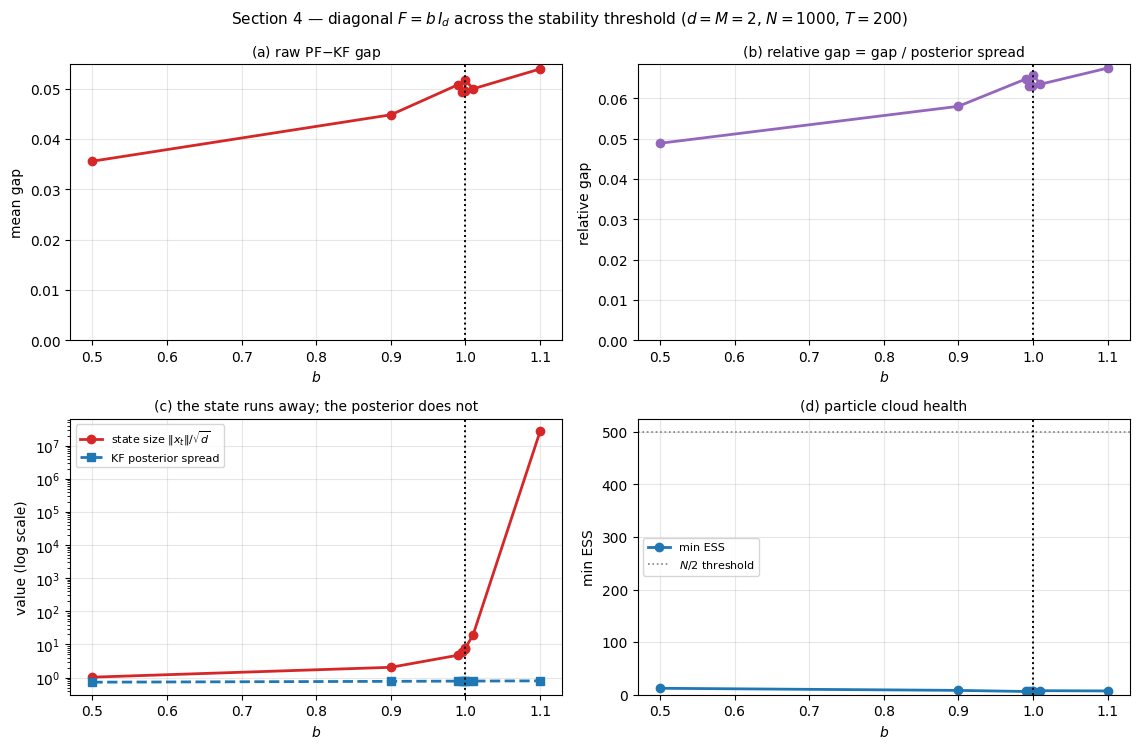

From b = 0.9 to b = 1.1:
  state size      2.048  ->  2.675e+07   (factor 1.31e+07)
  posterior spread 0.7725  ->  0.7991   (factor 1.034)
  relative gap    0.0580  ->  0.0675   (factor 1.163)


In [8]:
bs = [r["b"] for r in diag_sweep]
fig, axes = plt.subplots(2, 2, figsize=(11.5, 7.6))

def mark_threshold(ax):
    ax.axvline(1.0, color="black", ls=":", lw=1.4)

# (a) raw gap
ax = axes[0, 0]
ax.plot(bs, [r["mean_gap"] for r in diag_sweep], "o-", color=C_EXPLODE, lw=2)
mark_threshold(ax); ax.set_ylim(bottom=0)
ax.set_title("(a) raw PF$-$KF gap", fontsize=10)
ax.set_xlabel("$b$"); ax.set_ylabel("mean gap")

# (b) relative gap -- the primary metric
ax = axes[0, 1]
ax.plot(bs, [r["rel_gap"] for r in diag_sweep], "o-", color="tab:purple", lw=2)
mark_threshold(ax); ax.set_ylim(bottom=0)
ax.set_title("(b) relative gap = gap / posterior spread", fontsize=10)
ax.set_xlabel("$b$"); ax.set_ylabel("relative gap")

# (c) the state explodes while the posterior spread does not -- the key panel
ax = axes[1, 0]
ax.semilogy(bs, [r["state_sd"] for r in diag_sweep], "o-", color=C_EXPLODE, lw=2,
            label="state size $\\|x_t\\|/\\sqrt{d}$")
ax.semilogy(bs, [r["post_sd"] for r in diag_sweep], "s--", color=C_STABLE, lw=2,
            label="KF posterior spread")
mark_threshold(ax)
ax.set_title("(c) the state runs away; the posterior does not", fontsize=10)
ax.set_xlabel("$b$"); ax.set_ylabel("value (log scale)"); ax.legend(fontsize=8)

# (d) cloud health
ax = axes[1, 1]
ax.plot(bs, [r["min_ess"] for r in diag_sweep], "o-", color=C_STABLE, lw=2, label="min ESS")
ax.axhline(N_PART / 2, color="grey", ls=":", lw=1.2, label="$N/2$ threshold")
mark_threshold(ax); ax.set_ylim(bottom=0)
ax.set_title("(d) particle cloud health", fontsize=10)
ax.set_xlabel("$b$"); ax.set_ylabel("min ESS"); ax.legend(fontsize=8)

fig.suptitle(f"Section 4 — diagonal $F = b\\,I_d$ across the stability threshold "
             f"($d = M = {D}$, $N = {N_PART}$, $T = {T_MAIN}$)", fontsize=11)
plt.tight_layout(); plt.show()

lo = next(r for r in diag_sweep if r["b"] == 0.9)
hi = next(r for r in diag_sweep if r["b"] == 1.1)
print(f"From b = 0.9 to b = 1.1:")
print(f"  state size      {lo['state_sd']:.4g}  ->  {hi['state_sd']:.4g}   "
      f"(factor {hi['state_sd']/lo['state_sd']:.3g})")
print(f"  posterior spread {lo['post_sd']:.4f}  ->  {hi['post_sd']:.4f}   "
      f"(factor {hi['post_sd']/lo['post_sd']:.3f})")
print(f"  relative gap    {lo['rel_gap']:.4f}  ->  {hi['rel_gap']:.4f}   "
      f"(factor {hi['rel_gap']/lo['rel_gap']:.3f})")

**Conclusion.** **Panel (c) is the result, and it contradicts the expectation stated above the cell.** From
$b = 0.9$ to $b = 1.1$ the state size grows by a factor of $1.3 \times 10^{7}$ while the exact
posterior spread moves from $0.773$ to $0.799$ — a factor of $1.034$. The posterior does not care
that the model has become explosive, so the particle filter has no reason to either: the relative gap
goes $0.0580 \to 0.0675$, a $16\%$ rise across a sweep in which the signal grew seven orders of
magnitude, and the minimum ESS is unchanged ($8.2 \to 7.2$).

The state-relative gap *falls* by a factor of $38$ ($3.39 \times 10^{-2} \to 8.81 \times 10^{-4}$),
but for the uninteresting reason that its denominator is exploding. That is precisely why the
relative gap — error against posterior spread — is the primary metric and the state-relative one is
kept only as the Section 8 diagnostic.

The lesson worth carrying forward: **it is the posterior, not the state, that sets the scale of the
filtering problem.** An unstable model does not imply a difficult inference problem.

---
## Section 5 — Experiment 3: coupled $F$, same spectral radius

Experiment 2 used independent coordinates. Now put the coupling back: `coupling = 0.2`, so the base
matrix at $d = 2$ is

$$\text{base} = \begin{pmatrix} 1 & 0.2 \\ 0.2 & 1 \end{pmatrix}, \qquad
F = \frac{b}{\rho(\text{base})}\,\text{base},$$

and the two coordinates now push each other. Because of the rescaling, $\rho(F) = b$ in both
experiments, so **the threshold is at the same place**. The question is whether anything else differs.

It does, and it is worth predicting before looking. For the symmetric tridiagonal base the
eigenvalues are distinct, so after rescaling only the *largest* equals $b$ and the rest are strictly
smaller. That gives a structural difference the diagonal case cannot have:

- **Diagonal $F$:** every eigenvalue is $b$, so at $b > 1$ **all $d$ directions** become explosive together.
- **Coupled $F$:** only the leading eigenvalue is $b$, so at $b > 1$ **only some directions** are explosive and the rest remain stable.

The eigenvalue table below makes that concrete, and the sweep then asks whether the filter notices.

In [9]:
print(f"Eigenvalues of F at d = {D}, comparing coupling = 0.0 and 0.2:\n")
hdr = f"{'b':>6}{'|eig| (coupling=0)':>24}{'# explosive':>13}{'|eig| (coupling=0.2)':>26}{'# explosive':>13}"
print(hdr); print("-" * len(hdr))
for b in B_GRID:
    F0, _, _, _ = build_model(D, M, b=b, coupling=0.0)
    Fc, _, _, _ = build_model(D, M, b=b, coupling=0.2)
    e0 = np.sort(np.abs(np.linalg.eigvals(F0)))[::-1]
    ec = np.sort(np.abs(np.linalg.eigvals(Fc)))[::-1]
    print(f"{b:>6}{str(np.round(e0, 4)):>24}{(e0 > 1).sum():>13}"
          f"{str(np.round(ec, 4)):>26}{(ec > 1).sum():>13}")
print("\nBoth have rho(F) = b, so the threshold is identical. But at b > 1 the diagonal model")
print("has every direction explosive, while the coupled model has only the leading one.")

Eigenvalues of F at d = 2, comparing coupling = 0.0 and 0.2:

     b      |eig| (coupling=0)  # explosive      |eig| (coupling=0.2)  # explosive
----------------------------------------------------------------------------------
   0.5               [0.5 0.5]            0           [0.5    0.3333]            0
   0.9               [0.9 0.9]            0                 [0.9 0.6]            0
  0.99             [0.99 0.99]            0               [0.99 0.66]            0
 0.995           [0.995 0.995]            0           [0.995  0.6633]            0
 0.999           [0.999 0.999]            0             [0.999 0.666]            0
   1.0                 [1. 1.]            0           [1.     0.6667]            0
  1.01             [1.01 1.01]            2           [1.01   0.6733]            1
   1.1               [1.1 1.1]            2           [1.1    0.7333]            1

Both have rho(F) = b, so the threshold is identical. But at b > 1 the diagonal model
has every direction ex

Experiment 3 -- coupled F (coupling = 0.2), d = 2, M = 2, T = 200, N = 1000, 8 PF seeds:

     b     max |x|   mean gap   post sd   rel gap  min ESS   resamp
-------------------------------------------------------------------
   0.5       3.444     0.0343    0.7228    0.0475     12.0    139.8
   0.9       6.345     0.0406    0.7554    0.0537     14.5    144.2
  0.99       11.45     0.0413    0.7644    0.0541      9.6    148.6
 0.995        13.9     0.0433    0.7650    0.0565     10.6    148.6
 0.999       17.29     0.0434    0.7654    0.0567     10.3    148.5
   1.0       18.46     0.0427    0.7655    0.0558     11.7    149.1
  1.01        51.3     0.0422    0.7665    0.0550     11.4    149.0
   1.1   4.763e+08     0.0461    0.7760    0.0594     11.9    152.6


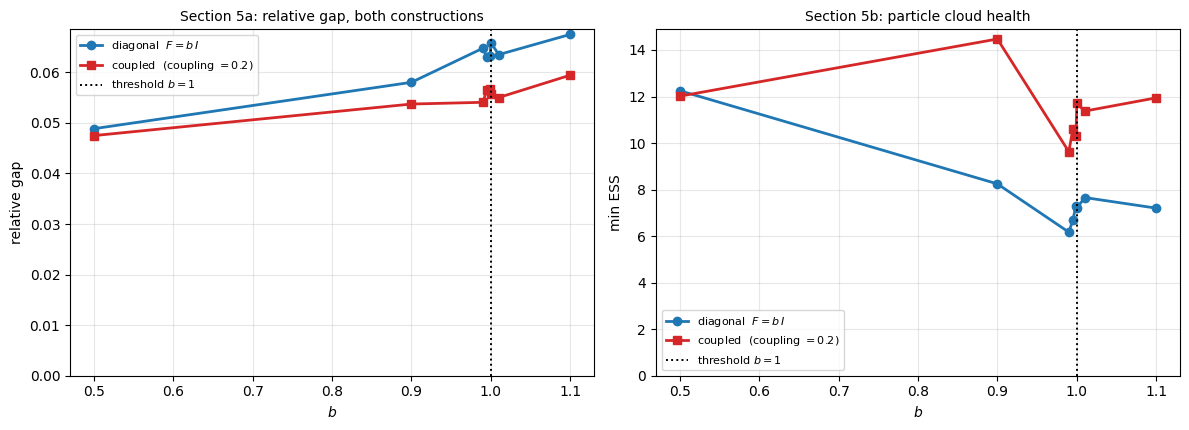

In [10]:
coup_sweep = sweep_b(B_GRID, coupling=0.2)

print(f"Experiment 3 -- coupled F (coupling = 0.2), d = {D}, M = {M}, "
      f"T = {T_MAIN}, N = {N_PART}, {N_SEEDS} PF seeds:\n")
hdr = (f"{'b':>6}{'max |x|':>12}{'mean gap':>11}{'post sd':>10}{'rel gap':>10}"
       f"{'min ESS':>9}{'resamp':>9}")
print(hdr); print("-" * len(hdr))
for r in coup_sweep:
    print(f"{r['b']:>6}{r['x_max']:>12.4g}{r['mean_gap']:>11.4f}{r['post_sd']:>10.4f}"
          f"{r['rel_gap']:>10.4f}{r['min_ess']:>9.1f}{r['resamp']:>9.1f}")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.4))
for sw, lbl, col, mk in ((diag_sweep, "diagonal  $F = b\\,I$", C_STABLE, "o"),
                         (coup_sweep, "coupled  (coupling $=0.2$)", C_EXPLODE, "s")):
    a1.plot([r["b"] for r in sw], [r["rel_gap"] for r in sw], mk + "-", color=col,
            lw=2, label=lbl)
    a2.plot([r["b"] for r in sw], [r["min_ess"] for r in sw], mk + "-", color=col,
            lw=2, label=lbl)
for ax, ttl, yl in ((a1, "Section 5a: relative gap, both constructions", "relative gap"),
                    (a2, "Section 5b: particle cloud health", "min ESS")):
    ax.axvline(1.0, color="black", ls=":", lw=1.4, label="threshold $b=1$")
    ax.set_xlabel("$b$"); ax.set_ylabel(yl); ax.set_title(ttl, fontsize=10)
    ax.set_ylim(bottom=0); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Conclusion.** The boundary is identical, as the rescaling guarantees, and the eigenvalue table makes the structural
difference concrete: at $b = 1.1$ the diagonal model has **2 of 2** directions explosive, the coupled
model **1 of 2** ($|\lambda| = 1.1$ and $0.733$). At $b = 1.0$ neither has any strictly explosive
direction, which is what sitting exactly on the threshold means.

The filter is essentially indifferent to the difference. The coupled relative gap goes
$0.0537 \to 0.0594$ from $b = 0.9$ to $1.1$ (factor $1.106$) against the diagonal's factor of
$1.163$ — both small — and the coupled cloud is marginally *healthier* (minimum ESS $11.9$ versus
$7.2$ at $b = 1.1$), with slightly fewer resampling events.

So coupling changes **how many directions cross the threshold** without changing **what crossing it
costs** — which is consistent with Section 4, where that cost was near zero to begin with. Whether
coupling matters when the explosive direction is *unobserved* is a different question, and Section 9
is where the observation geometry starts to bite.

> **Note.** Gerber's suggestion was to vary $F$ across the threshold. Running both the diagonal and
> the coupled construction is our own reading of it, chosen because the two differ in eigenvalue
> structure while sharing a boundary; it should be presented as an interpretation rather than as part
> of the original request.

---
## Section 6 — Entries versus eigenvalues

A short section making one point that is easy to state and easy to get wrong, and that the coupled
construction demonstrates for free.

Stability is a property of the **eigenvalues** of $F$, not of its entries. Because `build_model`
rescales by the spectral radius, a coupled $F$ with $\rho(F) = 1.1$ has every diagonal entry
*substantially below 1*: at $d = 4$ with `coupling = 0.3`, the diagonal is about $0.74$. Reading the
matrix entry by entry, every coordinate looks comfortably contractive. The state nevertheless
explodes, because the eigenvector combining the coordinates is amplified by $1.1$ at each step.

This is the multidimensional content of "$F$ is a matrix": you cannot read off stability by looking
at the diagonal, or at any single entry, or at a typical entry. You have to compute $\rho(F)$.

Coupled F at d = 4, coupling = 0.3:

  b = rho(F)    diag(F)   max entry    rho(F)     max |x_t|     verdict
-----------------------------------------------------------------------
         0.9     0.6059      0.6059    0.9000         6.882      stable
         1.0     0.6732      0.6732    1.0000         14.25    boundary
         1.1     0.7405      0.7405    1.1000     1.604e+08   EXPLOSIVE


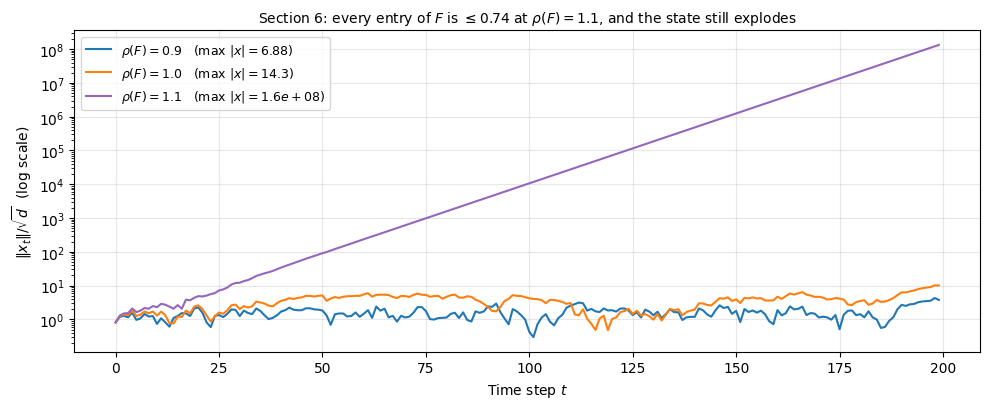

At rho(F) = 1.1 with d = 4, coupling = 0.3:
  every diagonal entry      = 0.7405
  largest entry anywhere    = 0.7405
  spectral radius           = 1.1000  <-- the only number that decides


In [11]:
d6, coup6 = 4, 0.3
print(f"Coupled F at d = {d6}, coupling = {coup6}:\n")
hdr = f"{'b = rho(F)':>12}{'diag(F)':>11}{'max entry':>12}{'rho(F)':>10}{'max |x_t|':>14}{'verdict':>12}"
print(hdr); print("-" * len(hdr))
traj6 = {}
for b in [0.9, 1.0, 1.1]:
    F, Q, H, R = build_model(d6, d6, b=b, coupling=coup6)
    x, _ = simulate_data_md(F, Q, H, R, T=T_MAIN, seed=DATA_SEED)
    traj6[b] = x
    verdict = "stable" if b < 1 else ("boundary" if b == 1 else "EXPLOSIVE")
    print(f"{b:>12}{np.diag(F)[0]:>11.4f}{np.abs(F).max():>12.4f}"
          f"{np.max(np.abs(np.linalg.eigvals(F))):>10.4f}"
          f"{np.abs(x).max():>14.4g}{verdict:>12}")

F11, _, _, _ = build_model(d6, d6, b=1.1, coupling=coup6)
fig, ax = plt.subplots(figsize=(10, 4.2))
for b in [0.9, 1.0, 1.1]:
    size = np.linalg.norm(traj6[b], axis=1) / np.sqrt(d6)
    ax.semilogy(np.arange(T_MAIN), size + 1e-3, lw=1.5, color=B_COLOR[b],
                label=f"$\\rho(F) = {b}$   (max $|x| = {np.abs(traj6[b]).max():.3g}$)")
ax.set_title(f"Section 6: every entry of $F$ is $\\leq {np.abs(F11).max():.2f}$ at "
             f"$\\rho(F) = 1.1$, and the state still explodes", fontsize=10)
ax.set_xlabel("Time step $t$"); ax.set_ylabel("$\\|x_t\\|/\\sqrt{d}$  (log scale)")
ax.legend(fontsize=9, loc="upper left")
plt.tight_layout(); plt.show()

print(f"At rho(F) = 1.1 with d = {d6}, coupling = {coup6}:")
print(f"  every diagonal entry      = {np.diag(F11)[0]:.4f}")
print(f"  largest entry anywhere    = {np.abs(F11).max():.4f}")
print(f"  spectral radius           = {np.max(np.abs(np.linalg.eigvals(F11))):.4f}  <-- the only number that decides")

**Conclusion.** At $d = 4$ with `coupling = 0.3` and $\rho(F) = 1.1$, **every entry of $F$ — diagonal and
off-diagonal alike — is $0.7405$ or smaller**, and the state still reaches $1.6 \times 10^{8}$ over
200 steps. Read entry by entry the matrix looks firmly contractive; the eigenvector mixing the
coordinates is nonetheless amplified by $1.1$ at every step.

No entry of $F$, and no summary of its entries, determines stability. Only $\rho(F)$ does. This is
the concrete content of "$F$ is a matrix, not a number": the one-dimensional intuition that
$b < 1$ means decay generalises to **eigenvalues**, not to coefficients.

---
## Section 7 — Error over time across the threshold

Sections 4 and 5 ran to $T = 200$. The property we actually care about is whether the error
**stays** bounded as the filter runs, since each step's approximation is built on the previous one.
Part 3 established that at $b = 0.9$ over $T = 2000$. Two extensions are needed.

**7a. Does it survive at and above the threshold?** Run $b = 0.9, 1.0, 1.01$ to $T = 2000$. We keep
to $b \le 1.01$ here for a reason established in Section 8: at larger $b$ the state outgrows float64
precision before $t = 2000$ and the measurement stops being real. Method as in Part 3 — split the
run into blocks of 100 steps, average the gap within each block, and fit a line through the block
means. A stable filter gives a slope indistinguishable from zero.

**7b. Does it survive where the particle cloud collapses?** This closes a gap in Part 3 rather than
in Part 2. Part 3 ran long horizons only at $(d, M) = (2,2), (2,4), (4,2)$ — all small. The setting
where Part 2 found the cloud actually collapsing, $d = 4$ with $M = 16$ and a minimum ESS near 1, was
only ever run at $T = 100$. That is precisely where accumulating error would be most likely, so it is
the one worth checking. Noted as an addition of our own, not part of the $F$ question.

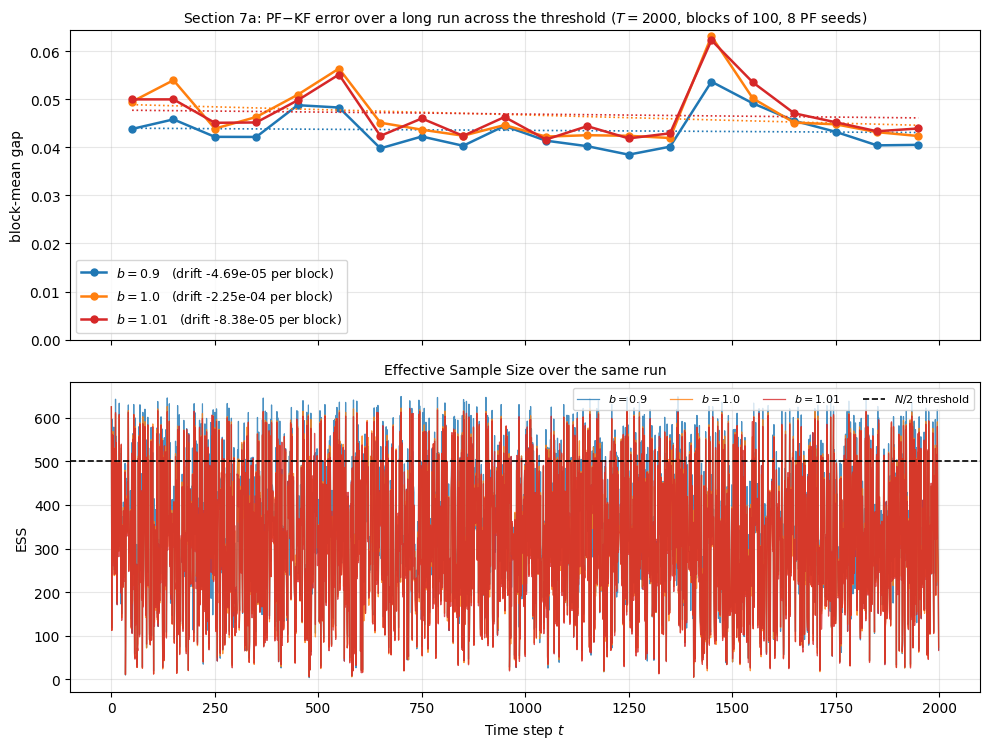

Does the error drift upward over time? (T = 2000)

     b   mean gap   1st half   2nd half   ratio   drift/1000 steps
------------------------------------------------------------------
   0.9    0.04354    0.04379    0.04328   0.988             -1.08%
   1.0    0.04674    0.04769    0.04579   0.960             -4.82%
  1.01    0.04693    0.04723    0.04662   0.987             -1.79%

A ratio near 1.0 and a drift near 0% mean the error is flat in t: the filter is stable.


In [12]:
NB = 20   # blocks, as in Part 3
long_res = {}
for b in B_REF:
    runs = [run_case(D, M, N=N_PART, T=T_LONG, b=b, coupling=0.0,
                     data_seed=DATA_SEED, pf_seed=s) for s in range(N_SEEDS)]
    gap = np.mean([r["gap"] for r in runs], axis=0)
    ess = np.mean([r["ess"] for r in runs], axis=0)
    blocks = gap.reshape(NB, -1).mean(axis=1)
    long_res[b] = {"gap": gap, "ess": ess, "blocks": blocks,
                   "slope": np.polyfit(np.arange(NB), blocks, 1)[0]}

block_mid = (np.arange(NB) + 0.5) * (T_LONG // NB)
fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 7.6), sharex=True)
for b in B_REF:
    L = long_res[b]
    a1.plot(block_mid, L["blocks"], "o-", color=B_COLOR[b], lw=1.8, ms=5,
            label=f"$b = {b}$   (drift {L['slope']:+.2e} per block)")
    fit = np.poly1d(np.polyfit(np.arange(NB), L["blocks"], 1))(np.arange(NB))
    a1.plot(block_mid, fit, ":", color=B_COLOR[b], lw=1.2)
    a2.plot(np.arange(T_LONG), L["ess"], lw=0.9, color=B_COLOR[b], alpha=0.8, label=f"$b = {b}$")
a1.set_ylim(bottom=0)
a1.set_title(f"Section 7a: PF$-$KF error over a long run across the threshold "
             f"($T = {T_LONG}$, blocks of {T_LONG//NB}, {N_SEEDS} PF seeds)", fontsize=10)
a1.set_ylabel("block-mean gap"); a1.legend(fontsize=9)
a2.axhline(N_PART / 2, color="black", ls="--", lw=1.2, label="$N/2$ threshold")
a2.set_title("Effective Sample Size over the same run", fontsize=10)
a2.set_xlabel("Time step $t$"); a2.set_ylabel("ESS"); a2.legend(fontsize=8, ncol=4)
plt.tight_layout(); plt.show()

print(f"Does the error drift upward over time? (T = {T_LONG})\n")
hdr = f"{'b':>6}{'mean gap':>11}{'1st half':>11}{'2nd half':>11}{'ratio':>8}{'drift/1000 steps':>19}"
print(hdr); print("-" * len(hdr))
for b in B_REF:
    g = long_res[b]["gap"]; h = len(g) // 2
    h1, h2 = g[:h].mean(), g[h:].mean()
    drift = long_res[b]["slope"] * (1000 / (T_LONG // NB)) / g.mean() * 100
    print(f"{b:>6}{g.mean():>11.5f}{h1:>11.5f}{h2:>11.5f}{h2/h1:>8.3f}{drift:>18.2f}%")
print("\nA ratio near 1.0 and a drift near 0% mean the error is flat in t: the filter is stable.")

In [13]:
# --- 7b. Does stability survive where the particle cloud has collapsed? ---
# Part 3 ran long horizons only at small (d, M). The collapsed-cloud setting (d=4, M=16)
# was only ever run at T = 100. Fewer seeds here because these runs are the expensive ones.
N_SEEDS_7B = 4
hard_cases = [(4, 1, "under-observed"), (4, 4, "balanced"),
              (4, 16, "over-observed (cloud collapses)"), (16, 1, "high state dimension")]

print(f"7b. Time-stability at the dimensions where Part 2 found degeneracy "
      f"(b = 0.9, T = {T_LONG}, {N_SEEDS_7B} seeds):\n")
hdr = f"{'d':>3}{'M':>4}{'1st half':>11}{'2nd half':>11}{'ratio':>8}{'min ESS':>9}{'resamp':>9}  regime"
print(hdr); print("-" * (len(hdr) + 8))
for d, m, label in hard_cases:
    runs = [run_case(d, m, N=N_PART, T=T_LONG, b=0.9, coupling=0.0,
                     data_seed=DATA_SEED, pf_seed=s) for s in range(N_SEEDS_7B)]
    g = np.mean([r["gap"] for r in runs], axis=0); h = len(g) // 2
    h1, h2 = g[:h].mean(), g[h:].mean()
    print(f"{d:>3}{m:>4}{h1:>11.5f}{h2:>11.5f}{h2/h1:>8.3f}"
          f"{np.mean([r['min_ess'] for r in runs]):>9.1f}"
          f"{np.mean([r['resampled'].sum() for r in runs]):>9.0f}  {label}")
print("\nESS near 1 means the posterior is being carried by a single particle.")
print("The ratio column says whether that costs anything in time-stability.")

7b. Time-stability at the dimensions where Part 2 found degeneracy (b = 0.9, T = 2000, 4 seeds):

  d   M   1st half   2nd half   ratio  min ESS   resamp  regime
-----------------------------------------------------------------------


  4   1    0.17838    0.17455   0.978      7.2      991  under-observed


  4   4    0.09150    0.09353   1.022      1.8     2000  balanced


  4  16    0.10093    0.10846   1.075      1.0     2000  over-observed (cloud collapses)


 16   1    0.20071    0.22160   1.104      4.1      967  high state dimension

ESS near 1 means the posterior is being carried by a single particle.
The ratio column says whether that costs anything in time-stability.


**Conclusion.** **7a — the threshold does not introduce accumulation.** Over $T = 2000$ at $b = 0.9$, $1.0$ and
$1.01$, the second-half / first-half ratios are $0.988$, $0.960$ and $0.987$ — all slightly *below*
$1$ — and the fitted drift is $-1.1\%$, $-4.8\%$ and $-1.8\%$ per 1000 steps, negative in every case.
The ESS keeps sawtoothing against the $N/2$ threshold at step 2000 exactly as at step 1. Whatever
crossing the threshold does, it does not make errors compound.

**7b — and stability survives even where the cloud has collapsed.** This is the more striking half.
At $d = 4$, $M = 16$ the minimum ESS is $1.0$ and resampling fires at all 2000 steps — the posterior
is being carried by a single particle — and the ratio is still $1.075$. The balanced and
under-observed cases give $1.022$ and $0.978$.

So **degeneracy and accumulation are independent failure modes.** ESS collapse raises the error
*level* (mean gaps of $0.092$, $0.178$ and $0.101$ across the cases) without destabilising it in
*time*. That is worth stating because the two are easy to conflate: a filter running on one effective
particle is a bad filter, but not a diverging one.

One caveat, stated rather than glossed: $d = 16$ gives the largest ratio at $1.104$, and with only
4 seeds that is within noise of the others. A seed-averaged check would be needed before reading
anything into it. Section 7b is our own addition, closing a gap in Part 3 — which ran long horizons
only at small $(d, M)$ — rather than part of the $F$ question.

---
## Section 8 — The numerical limit: where the measurement stops being real

This section exists because the obvious version of this experiment produces a convincing, and
entirely false, result.

Float64 carries about 16 significant decimal digits. At $b = 1.1$ the state grows like $1.1^t$, so by
$t = 2000$ it is of order $10^{83}$. The PF–KF gap we are trying to measure is of order $1$. Asking
for a difference of order $1$ between two numbers of order $10^{83}$ asks for 83 digits of agreement
from a format that has 16 — the answer is not inaccurate, it is **entirely round-off**. This is
catastrophic cancellation, and the signature is unmistakable once you look for it:

$$\text{apparent gap} \;\approx\; |x|_{\max} \times \varepsilon, \qquad \varepsilon \approx 2.2 \times 10^{-16}.$$

Run the naive experiment and you get a plot of error growing by sixty-six orders of magnitude as
$b$ crosses 1 — a dramatic and completely spurious confirmation of "instability". The table below
runs it deliberately, then shows two ways of telling that nothing real happened: the predicted
cancellation floor, and the state-relative gap, which correctly reports $\sim 10^{-16}$ throughout.

The practical consequence for every other section: keep $b^T \lesssim 10^{10}$, which leaves roughly
six digits of headroom. That makes the usable horizon a function of $b$ — long runs at $b$ near 1,
short runs further out — which is why Section 7a stops at $b = 1.01$.

In [14]:
EPS = np.finfo(float).eps
print(f"Deliberately running past the precision limit (d = M = {D}, N = {N_PART}):\n")
hdr = (f"{'b':>6}{'T':>7}{'max |x|':>12}{'mean gap':>12}{'|x|*eps':>12}"
       f"{'gap/state':>12}{'real?':>8}")
print(hdr); print("-" * len(hdr))
for b in [0.9, 1.0, 1.01, 1.05, 1.1]:
    for T in [T_MAIN, 500, T_LONG]:
        r = run_case(D, M, N=N_PART, T=T, b=b, coupling=0.0,
                     data_seed=DATA_SEED, pf_seed=PF_SEED)
        xm = np.abs(r["x"]).max()
        floor = xm * EPS
        rs = rel_to_state(r).mean()
        real = "yes" if r["mean_gap"] > 10 * floor else "NO"
        print(f"{b:>6}{T:>7}{xm:>12.3g}{r['mean_gap']:>12.4g}{floor:>12.3g}"
              f"{rs:>12.2e}{real:>8}")

print(f"\nmachine epsilon = {EPS:.3g}")
print("Where 'real?' is NO, the measured gap is the same size as |x|*eps -- it IS the round-off,")
print("not the filter's error. The 'gap/state' column stays at ~1e-16 there, correctly reporting")
print("that nothing happened. Below the limit, gap/state is orders of magnitude larger than eps.")

Deliberately running past the precision limit (d = M = 2, N = 1000):

     b      T     max |x|    mean gap     |x|*eps   gap/state   real?
---------------------------------------------------------------------
   0.9    200        6.92     0.04373    1.54e-15    3.49e-02     yes
   0.9    500        6.92     0.04586    1.54e-15    3.35e-02     yes


   0.9   2000        8.39     0.04351    1.86e-15    3.17e-02     yes
   1.0    200        21.3     0.05234    4.74e-15    8.02e-03     yes
   1.0    500        33.9     0.04923    7.52e-15    5.05e-03     yes


   1.0   2000        37.2     0.04636    8.26e-15    5.03e-03     yes
  1.01    200          52     0.04858    1.15e-14    4.24e-03     yes
  1.01    500    1.06e+03     0.04697    2.35e-13    1.86e-03     yes


  1.01   2000     3.2e+09     0.04725    7.11e-07    4.67e-04     yes
  1.05    200    6.32e+04     0.05472     1.4e-11    1.57e-03     yes
  1.05    500    1.44e+11      0.0502    3.19e-05    6.29e-04     yes


/Users/szemingchak/Documents/GitHub/particle-filter-stability/filters.py:731: RuntimeWarning: divide by zero encountered in log
  log_w = -0.5 * quad + np.log(weights)


  1.05   2000    8.74e+42   9.583e+26    1.94e+27    1.57e-04      NO
   1.1    200    5.75e+08     0.04727    1.28e-07    6.55e-04     yes
   1.1    500     1.5e+21   3.286e+05    3.34e+05    2.62e-04      NO


   1.1   2000    1.85e+83   9.936e+66     4.1e+67    6.55e-05      NO

machine epsilon = 2.22e-16
Where 'real?' is NO, the measured gap is the same size as |x|*eps -- it IS the round-off,
not the filter's error. The 'gap/state' column stays at ~1e-16 there, correctly reporting
that nothing happened. Below the limit, gap/state is orders of magnitude larger than eps.


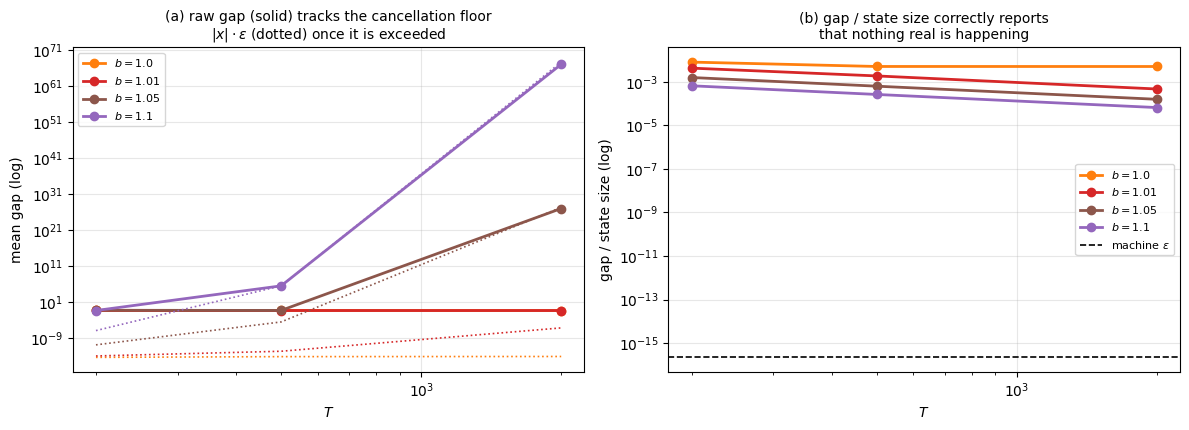

Usable horizon, keeping b^T <= 1e10 (about six digits of headroom):

       b   max usable T
     0.5           2000
     0.9           2000
    0.99           2000
   0.995           2000
   0.999           2000
     1.0           2000
    1.01           2000
     1.1            241


In [15]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.4))

Ts = np.array([T_MAIN, 500, T_LONG])
for b in [1.0, 1.01, 1.05, 1.1]:
    raw, floors, rels = [], [], []
    for T in Ts:
        r = run_case(D, M, N=N_PART, T=T, b=b, coupling=0.0,
                     data_seed=DATA_SEED, pf_seed=PF_SEED)
        raw.append(r["mean_gap"]); floors.append(np.abs(r["x"]).max() * EPS)
        rels.append(rel_to_state(r).mean())
    a1.loglog(Ts, np.maximum(raw, 1e-20), "o-", color=B_COLOR[b], lw=2, label=f"$b = {b}$")
    a1.loglog(Ts, np.maximum(floors, 1e-20), ":", color=B_COLOR[b], lw=1.2)
    a2.loglog(Ts, rels, "o-", color=B_COLOR[b], lw=2, label=f"$b = {b}$")

a1.set_title("(a) raw gap (solid) tracks the cancellation floor\n$|x|\\cdot\\varepsilon$ (dotted) once it is exceeded",
             fontsize=10)
a1.set_xlabel("$T$"); a1.set_ylabel("mean gap (log)"); a1.legend(fontsize=8)
a2.axhline(EPS, color="black", ls="--", lw=1.2, label="machine $\\varepsilon$")
a2.set_title("(b) gap / state size correctly reports\nthat nothing real is happening", fontsize=10)
a2.set_xlabel("$T$"); a2.set_ylabel("gap / state size (log)"); a2.legend(fontsize=8)

plt.tight_layout(); plt.show()

print("Usable horizon, keeping b^T <= 1e10 (about six digits of headroom):\n")
print(f"{'b':>8}{'max usable T':>15}")
for b in B_GRID:
    print(f"{b:>8}{T_safe(b):>15}")

**Conclusion.** **The signature is exact.** Wherever the `real?` column reads NO, the measured gap sits at the same
magnitude as $|x|\cdot\varepsilon$: at $b = 1.05$, $T = 2000$ the apparent gap is
$9.58 \times 10^{26}$ against a cancellation floor of $1.94 \times 10^{27}$; at $b = 1.1$,
$T = 2000$ it is $9.94 \times 10^{66}$ against $4.1 \times 10^{67}$. These are not large errors —
they are the spacing between adjacent float64 numbers at that magnitude.

Run naively, this experiment reports the PF–KF error growing by **sixty-six orders of magnitude** as
$b$ crosses 1: a dramatic, entirely spurious confirmation of instability, and exactly the result one
would be tempted to present. Two independent tells catch it. The predicted floor $|x|\cdot\varepsilon$
matches the apparent gap wherever the measurement has failed, and the state-relative gap stays at
$10^{-4}$–$10^{-5}$ throughout, correctly reporting that nothing is happening.

The marginal case is instructive: $b = 1.01$ at $T = 2000$ has a floor of $7.11 \times 10^{-7}$
against a gap of $0.047$ — five orders of headroom, so still usable. $b = 1.1$ is safe only to
$T \approx 241$. That is why Section 7a stops at $b = 1.01$ and the sweeps run to $T = 200$: the
usable horizon is a function of $b$, and the two cannot both be pushed at once.

---
## Section 9 — Experiment 4: when the observations do not constrain the explosive direction

Everything so far has been **fully observed**: $M = d$ with $H = I$, so every coordinate is measured
at every step. Under that condition the Kalman filter's posterior spread turned out to be almost
completely insensitive to $b$, and the particle filter inherited that.

That is not a coincidence, and it is not a property of stability. It is a property of
**detectability**: the Kalman filter's posterior covariance converges to a bounded steady state even
for an explosive $F$, provided the observations constrain the explosive directions. Standard filtering
theory gives this (see e.g. Anderson & Moore, *Optimal Filtering*), and Sections 2–7 are an
illustration of it rather than a discovery.

So the sharp question is what happens when that condition **fails**. Take $d = 2$, $M = 1$,
`coupling = 0.0`. Then $F = b\,I_2$ and $H = \begin{pmatrix} 1 & 0\end{pmatrix}$: coordinate $x_0$ is
measured at every step, and coordinate $x_1$ is **never measured at all**. With no coupling there is
no indirect route to it either — the data say literally nothing about $x_1$.

Below the threshold that is survivable: the unmeasured coordinate's uncertainty settles at its
stationary variance, which is finite. At $b \ge 1$ there is no stationary variance to settle at.
Nothing bounds the posterior uncertainty in that direction, and the exact posterior itself — not
merely its particle approximation — should become unbounded.

We report the Kalman posterior variance **per coordinate**, because the aggregate `post_sd` and
therefore `rel_gap` stop being meaningful here: once the denominator is itself diverging, a ratio
against it says nothing.

In [16]:
d9, M9, T9 = 2, 1, 150
print(f"d = {d9}, M = {M9}, coupling = 0: coordinate 0 observed, coordinate 1 NEVER observed")
print(f"(T = {T9}, N = {N_PART})\n")
hdr = (f"{'b':>6}{'P[0,0] end':>13}{'P[1,1] end':>14}{'ratio':>12}"
       f"{'post sd':>11}{'min ESS':>9}")
print(hdr); print("-" * len(hdr))
res9 = {}
for b in B_GRID:
    r = run_case(d9, M9, N=N_PART, T=T9, b=b, coupling=0.0,
                 data_seed=DATA_SEED, pf_seed=PF_SEED)
    res9[b] = r
    P = r["kf_cov"][-1]
    print(f"{b:>6}{P[0, 0]:>13.4f}{P[1, 1]:>14.4g}{P[1, 1]/P[0, 0]:>12.4g}"
          f"{r['post_sd']:>11.4g}{r['min_ess']:>9.1f}")

# Fully observed, same b, for contrast.
print(f"\nSame b, but FULLY observed (d = M = {d9}) -- the explosive direction is measured:\n")
print(f"{'b':>6}{'P[0,0] end':>13}{'P[1,1] end':>14}{'post sd':>11}")
for b in B_GRID:
    r = run_case(d9, d9, N=N_PART, T=T9, b=b, coupling=0.0,
                 data_seed=DATA_SEED, pf_seed=PF_SEED)
    P = r["kf_cov"][-1]
    print(f"{b:>6}{P[0, 0]:>13.4f}{P[1, 1]:>14.4f}{r['post_sd']:>11.4f}")

d = 2, M = 1, coupling = 0: coordinate 0 observed, coordinate 1 NEVER observed
(T = 150, N = 1000)

     b   P[0,0] end    P[1,1] end       ratio    post sd  min ESS
-----------------------------------------------------------------
   0.5       0.5311         1.333        2.51     0.9647     65.1
   0.9       0.5974         5.263        8.81      1.687     65.5
  0.99       0.6159         47.79       77.59       4.09     56.4
 0.995       0.6170         77.97       126.4      4.787     52.5
 0.999       0.6178         129.7       209.9      5.587     75.6
   1.0       0.6180           150       242.7      5.834     50.7
  1.01       0.6201         934.7        1507      10.09     56.0
   1.1       0.6395     1.246e+13   1.949e+13  1.831e+05     60.0

Same b, but FULLY observed (d = M = 2) -- the explosive direction is measured:

     b   P[0,0] end    P[1,1] end    post sd
   0.5       0.5311        0.5311     0.7286
   0.9       0.5974        0.5974     0.7724
  0.99       0.6159     

  1.01       0.6201        0.6201     0.7869
   1.1       0.6395        0.6395     0.7989


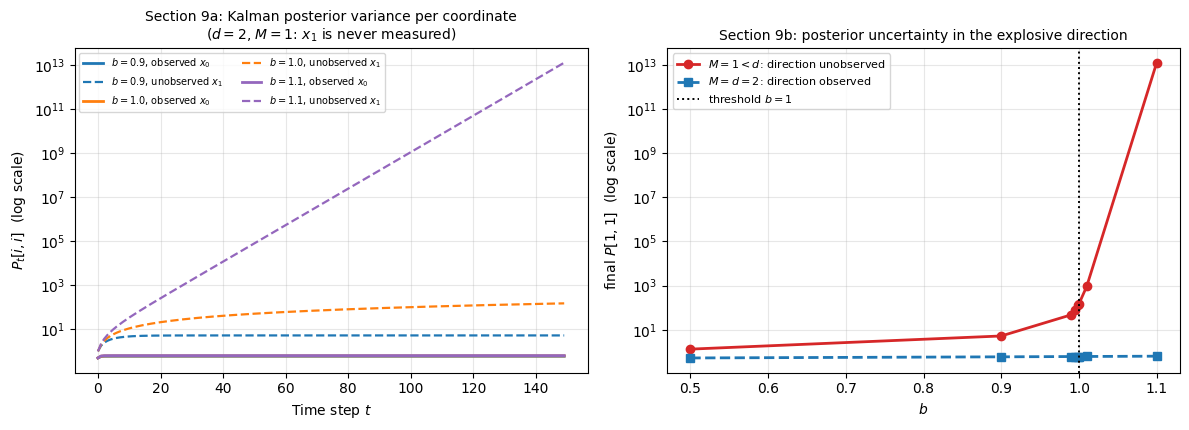

Final posterior variance in coordinate 1, as b crosses the threshold:

       b    unobserved (M<d)    observed (M=d)      factor
     0.5               1.333            0.5311        2.51
     0.9               5.263            0.5974        8.81
    0.99               47.79            0.6159       77.59
   0.995               77.97            0.6170       126.4
   0.999               129.7            0.6178       209.9
     1.0                 150            0.6180       242.7
    1.01               934.7            0.6201        1507
     1.1           1.246e+13            0.6395   1.949e+13

When the explosive direction is measured, the posterior is bounded and barely moves.
When it is not, the exact posterior itself diverges -- no particle filter can fix that,
because there is nothing wrong with the particle filter.


In [17]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.4))

# Posterior variance over time, per coordinate, under-observed.
for b in [0.9, 1.0, 1.1]:
    P = res9[b]["kf_cov"]
    a1.semilogy(np.arange(T9), P[:, 0, 0], "-", color=B_COLOR[b], lw=2,
                label=f"$b={b}$, observed $x_0$")
    a1.semilogy(np.arange(T9), np.maximum(P[:, 1, 1], 1e-3), "--", color=B_COLOR[b], lw=1.6,
                label=f"$b={b}$, unobserved $x_1$")
a1.set_title(f"Section 9a: Kalman posterior variance per coordinate\n($d={d9}$, $M={M9}$: "
             f"$x_1$ is never measured)", fontsize=10)
a1.set_xlabel("Time step $t$"); a1.set_ylabel("$P_t[i,i]$  (log scale)")
a1.legend(fontsize=7, ncol=2, loc="upper left")

# The headline contrast: final unobserved variance vs b, both observation regimes.
bs9 = B_GRID
under = [res9[b]["kf_cov"][-1][1, 1] for b in bs9]
full = [run_case(d9, d9, N=N_PART, T=T9, b=b, coupling=0.0,
                 data_seed=DATA_SEED, pf_seed=PF_SEED)["kf_cov"][-1][1, 1] for b in bs9]
a2.semilogy(bs9, under, "o-", color=C_EXPLODE, lw=2, label=f"$M={M9} < d$: direction unobserved")
a2.semilogy(bs9, full, "s--", color=C_STABLE, lw=2, label=f"$M=d={d9}$: direction observed")
a2.axvline(1.0, color="black", ls=":", lw=1.4, label="threshold $b=1$")
a2.set_title("Section 9b: posterior uncertainty in the explosive direction", fontsize=10)
a2.set_xlabel("$b$"); a2.set_ylabel("final $P[1,1]$  (log scale)"); a2.legend(fontsize=8)

plt.tight_layout(); plt.show()

print("Final posterior variance in coordinate 1, as b crosses the threshold:\n")
print(f"{'b':>8}{'unobserved (M<d)':>20}{'observed (M=d)':>18}{'factor':>12}")
for b, u, f in zip(bs9, under, full):
    print(f"{b:>8}{u:>20.4g}{f:>18.4f}{u/f:>12.4g}")
print("\nWhen the explosive direction is measured, the posterior is bounded and barely moves.")
print("When it is not, the exact posterior itself diverges -- no particle filter can fix that,")
print("because there is nothing wrong with the particle filter.")

**Conclusion.** **This is where something genuinely breaks — and it is not the particle filter.**

With the explosive direction **measured**, the final posterior variance in that coordinate is
$0.6395$ at $b = 1.1$, essentially unchanged from $0.5974$ at $b = 0.9$. With it **unmeasured**, the
same quantity is $1.246 \times 10^{13}$ — a factor of $1.9 \times 10^{13}$ larger — while the
*observed* coordinate sits unchanged at $0.6395$. The divergence is already building below the
threshold ($5.26 \to 47.8 \to 150$ as $b$ goes $0.9 \to 0.99 \to 1.0$, tracking the stationary
variance as it diverges) and becomes unbounded beyond it.

The crucial point is that this is a property of the **exact posterior**, computed by the Kalman
filter, not of its particle approximation. The minimum ESS is a healthy $50$–$65$ throughout —
*better* than in the fully observed case — so there is nothing here for a better filter to fix.

**What bounds the filter is detectability, not stability.** An explosive model is harmless as long as
the observations constrain the explosive directions; when they do not, the posterior uncertainty
itself is unbounded and no number of particles helps. This also sharpens Part 2's result: $M < d$ was
the hard regime there because of irreducible uncertainty in unmeasured directions, and crossing the
threshold is precisely the setting in which that uncertainty stops being merely large and becomes
infinite.

---
## Section 10 — Error bars

Every number so far comes from one simulated dataset (seed 42), with the sweeps averaging only over
particle-filter seeds. Part 3 showed why that is not enough: re-running Part 2's three-regime
comparison on 30 independent datasets overturned one of its conclusions. The same discipline applies
here before claiming that the relative gap is flat across the threshold.

So: 30 independent datasets at each of $b = 0.9, 1.0, 1.01$, each with its own particle-filter seed,
reported as a mean with a 95% confidence interval, followed by a pairwise two-sample test. If the
intervals overlap, "flat across the threshold" is a fair description. If they separate, it is not —
and saying so is the point of doing this.

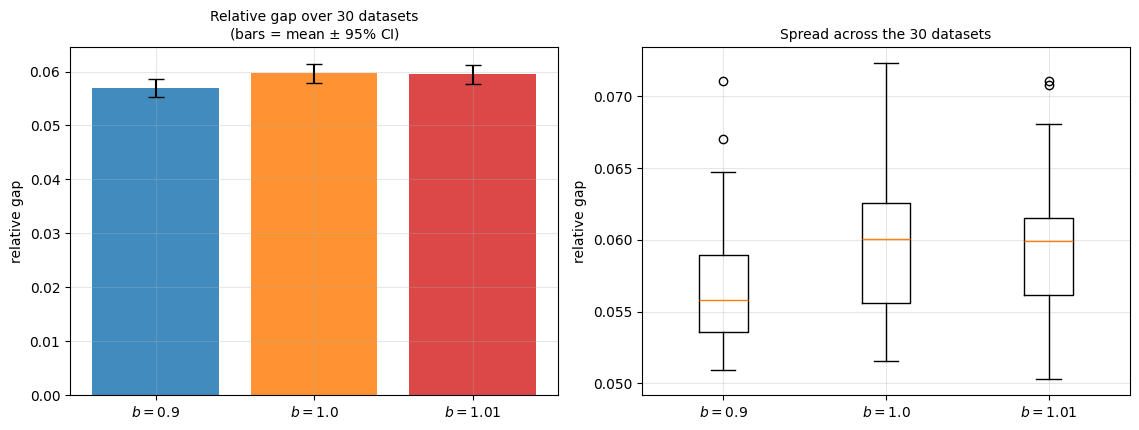

Relative gap over 30 independent datasets:

     b      mean      95% CI   min ESS
   0.9    0.0570      0.0017      11.6
   1.0    0.0596      0.0018      12.2
  1.01    0.0595      0.0017      11.0

Pairwise comparison (Welch two-sample t statistic, |t| > 2 is roughly p < 0.05):

comparison             difference       t   verdict
b=0.9 vs b=1.0            -0.0026   -2.12   clearly different
b=0.9 vs b=1.01           -0.0025   -2.03   clearly different
b=1.0 vs b=1.01           +0.0001    0.10   not distinguishable


In [18]:
ds = {}
for b in B_REF:
    runs = [run_case(D, M, N=N_PART, T=T_MAIN, b=b, coupling=0.0,
                     data_seed=100 + k, pf_seed=k) for k in range(N_DATASETS)]
    ds[b] = {"rel": np.array([r["rel_gap"] for r in runs]),
             "gap": np.array([r["mean_gap"] for r in runs]),
             "ess": np.array([r["min_ess"] for r in runs])}

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.5, 4.4))
xs = np.arange(len(B_REF))
means = [ds[b]["rel"].mean() for b in B_REF]
errs = [ci95(ds[b]["rel"]) for b in B_REF]
a1.bar(xs, means, yerr=errs, capsize=6, color=[B_COLOR[b] for b in B_REF], alpha=0.85)
a1.set_xticks(xs); a1.set_xticklabels([f"$b={b}$" for b in B_REF])
a1.set_title(f"Relative gap over {N_DATASETS} datasets\n(bars = mean $\\pm$ 95% CI)", fontsize=10)
a1.set_ylabel("relative gap")
a2.boxplot([ds[b]["rel"] for b in B_REF], tick_labels=[f"$b={b}$" for b in B_REF])
a2.set_title(f"Spread across the {N_DATASETS} datasets", fontsize=10)
a2.set_ylabel("relative gap")
plt.tight_layout(); plt.show()

print(f"Relative gap over {N_DATASETS} independent datasets:\n")
print(f"{'b':>6}{'mean':>10}{'95% CI':>12}{'min ESS':>10}")
for b in B_REF:
    print(f"{b:>6}{ds[b]['rel'].mean():>10.4f}{ci95(ds[b]['rel']):>12.4f}"
          f"{ds[b]['ess'].mean():>10.1f}")

import itertools
print("\nPairwise comparison (Welch two-sample t statistic, |t| > 2 is roughly p < 0.05):\n")
print(f"{'comparison':20s}{'difference':>13}{'t':>8}   verdict")
for a, b in itertools.combinations(B_REF, 2):
    ra, rb = ds[a]["rel"], ds[b]["rel"]
    diff = ra.mean() - rb.mean()
    se = np.sqrt(ra.var(ddof=1)/len(ra) + rb.var(ddof=1)/len(rb))
    t = diff / se
    print(f"{f'b={a} vs b={b}':20s}{diff:>+13.4f}{t:>8.2f}   "
          f"{'clearly different' if abs(t) > 2 else 'not distinguishable'}")

**Conclusion.** With `coupling = 0.0` the construction returns exactly $b\,I_d$: off-diagonal entries are zero to
machine precision and $\rho(F) = b$ at every $b$ tested. The default `coupling = 0.3` also gives
$\rho(F) = b$, but its diagonal is $0.6059$ at $d = 4$ — so "$F = 0.9 \times$ identity" as a literal
matrix requires `coupling = 0`, and Experiment 2 uses that.

`stationary_covariance` behaves in three distinct ways across the threshold. Below it the answer is a
genuine variance, growing from $1.33$ at $b = 0.5$ to $50.25$ at $b = 0.99$ — the stationary spread
diverging as the threshold is approached, which is itself the right behaviour. Exactly at $b = 1$ the
solve fails loudly with a `LinAlgError`. Above it the function returns a **negative** variance
($-49.75$ at $b = 1.01$, $-4.76$ at $b = 1.1$) and raises nothing at all. The silent failure is the
dangerous one, and it is the only thing in `filters.py` that this notebook has to route around.0

---
## Section 11 — Summary

With `coupling = 0.0` the construction returns exactly $b\,I_d$: off-diagonal entries are zero to
machine precision and $\rho(F) = b$ at every $b$ tested. The default `coupling = 0.3` also gives
$\rho(F) = b$, but its diagonal is $0.6059$ at $d = 4$ — so "$F = 0.9 \times$ identity" as a literal
matrix requires `coupling = 0`, and Experiment 2 uses that.

`stationary_covariance` behaves in three distinct ways across the threshold. Below it the answer is a
genuine variance, growing from $1.33$ at $b = 0.5$ to $50.25$ at $b = 0.99$ — the stationary spread
diverging as the threshold is approached, which is itself the right behaviour. Exactly at $b = 1$ the
solve fails loudly with a `LinAlgError`. Above it the function returns a **negative** variance
($-49.75$ at $b = 1.01$, $-4.76$ at $b = 1.1$) and raises nothing at all. The silent failure is the
dangerous one, and it is the only thing in `filters.py` that this notebook has to route around.1